In [1]:
import re
import nltk
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import ipywidgets as widgets
from IPython.display import display, clear_output

nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('omw-1.4')

print("All libraries imported successfully!")

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


All libraries imported successfully!


In [2]:
data = [

    # INTENT 1: DIABETES BASICS

    ("What is diabetes?", "diabetes_basics"),
    ("Explain diabetes mellitus.", "diabetes_basics"),
    ("What are the different types of diabetes?", "diabetes_basics"),
    ("What causes type 1 diabetes?", "diabetes_basics"),
    ("What causes type 2 diabetes?", "diabetes_basics"),
    ("What are the early symptoms of diabetes?", "diabetes_basics"),
    ("Can diabetes be hereditary?", "diabetes_basics"),
    ("What is gestational diabetes?", "diabetes_basics"),
    ("Why does diabetes occur in humans?", "diabetes_basics"),
    ("Can diabetes be prevented?", "diabetes_basics"),

    # INTENT 2: BLOOD GLUCOSE MANAGEMENT

    ("What is a normal blood sugar level?", "glucose_management"),
    ("How can I monitor my blood glucose?", "glucose_management"),
    ("What is fasting blood glucose?", "glucose_management"),
    ("What is HbA1c?", "glucose_management"),
    ("How often should diabetics check blood sugar?", "glucose_management"),
    ("What is post meal blood sugar?", "glucose_management"),
    ("How does a glucose meter work?", "glucose_management"),
    ("What is continuous glucose monitoring?", "glucose_management"),
    ("Why does blood sugar increase after eating?", "glucose_management"),
    ("How can I maintain stable glucose levels?", "glucose_management"),

    # INTENT 3: DIET AND NUTRITION

    ("What foods should diabetics eat?", "diet_nutrition"),
    ("Which fruits are suitable for diabetics?", "diet_nutrition"),
    ("Can diabetic patients eat rice?", "diet_nutrition"),
    ("Which foods should people with diabetes avoid?", "diet_nutrition"),
    ("Is a high fiber diet helpful for diabetes?", "diet_nutrition"),
    ("Can diabetics drink fruit juice?", "diet_nutrition"),
    ("What is a healthy breakfast for diabetics?", "diet_nutrition"),
    ("How does sugar affect diabetes?", "diet_nutrition"),
    ("Is whole wheat better than refined flour?", "diet_nutrition"),
    ("What is a balanced diabetic meal plan?", "diet_nutrition"),

    # INTENT 4: TREATMENT AND MEDICATION

    ("How is diabetes treated?", "treatment_medication"),
    ("What is insulin therapy?", "treatment_medication"),
    ("Why do diabetic patients take metformin?", "treatment_medication"),
    ("Can exercise help control diabetes?", "treatment_medication"),
    ("What are common diabetes medications?", "treatment_medication"),
    ("How does insulin work in the body?", "treatment_medication"),
    ("Can type 2 diabetes be managed without insulin?", "treatment_medication"),
    ("Why is regular exercise important for diabetics?", "treatment_medication"),
    ("Should diabetes medicine be taken daily?", "treatment_medication"),
    ("What lifestyle changes help manage diabetes?", "treatment_medication"),

    # INTENT 5: COMPLICATIONS AND EMERGENCIES

    ("What are the complications of diabetes?", "complications_emergencies"),
    ("What is diabetic neuropathy?", "complications_emergencies"),
    ("Can diabetes damage the kidneys?", "complications_emergencies"),
    ("What is diabetic retinopathy?", "complications_emergencies"),
    ("What is hypoglycemia?", "complications_emergencies"),
    ("What is hyperglycemia?", "complications_emergencies"),
    ("What are the symptoms of low blood sugar?", "complications_emergencies"),
    ("What happens when blood sugar becomes very high?", "complications_emergencies"),
    ("Can diabetes cause heart problems?", "complications_emergencies"),
    ("How can diabetic complications be prevented?", "complications_emergencies")

]

df = pd.DataFrame(data, columns=["query", "intent"])

print("Total queries:", len(df))
print("\nIntent distribution:")
print(df["intent"].value_counts())

print("\nDataset:")
display(df)

Total queries: 50

Intent distribution:
intent
diabetes_basics              10
glucose_management           10
diet_nutrition               10
treatment_medication         10
complications_emergencies    10
Name: count, dtype: int64

Dataset:


,query,intent
0,What is diabetes?,diabetes_basics
1,Explain diabetes mellitus.,diabetes_basics
2,What are the different types of diabetes?,diabetes_basics
3,What causes type 1 diabetes?,diabetes_basics
4,What causes type 2 diabetes?,diabetes_basics
5,What are the early symptoms of diabetes?,diabetes_basics
6,Can diabetes be hereditary?,diabetes_basics
7,What is gestational diabetes?,diabetes_basics
8,Why does diabetes occur in humans?,diabetes_basics
9,Can diabetes be prevented?,diabetes_basics


In [3]:
taxonomy = {

    "Diabetes Fundamentals": {

        "Diabetes Types": [
            "Type 1 Diabetes",
            "Type 2 Diabetes",
            "Gestational Diabetes"
        ],

        "Symptoms and Causes": [
            "Early Symptoms",
            "Risk Factors",
            "Genetic Factors"
        ]

    },

    "Blood Glucose Monitoring": {

        "Glucose Measurement": [
            "Fasting Glucose",
            "Post Meal Glucose",
            "HbA1c"
        ],

        "Monitoring Methods": [
            "Glucose Meter",
            "Continuous Glucose Monitoring"
        ]

    },

    "Lifestyle Management": {

        "Diet and Nutrition": [
            "Healthy Foods",
            "Meal Planning",
            "Food Restrictions"
        ],

        "Physical Activity": [
            "Exercise",
            "Weight Management"
        ]

    },

    "Clinical Management": {

        "Medication and Treatment": [
            "Insulin Therapy",
            "Oral Medication",
            "Lifestyle Treatment"
        ],

        "Complications": [
            "Hypoglycemia",
            "Hyperglycemia",
            "Kidney Complications",
            "Eye Complications",
            "Nerve Damage"
        ]

    }

}

def display_taxonomy(taxonomy):

    for major, subcategories in taxonomy.items():

        print("\n", major)

        for subcategory, concepts in subcategories.items():

            print("   |--", subcategory)

            for concept in concepts:
                print("       |--", concept)


display_taxonomy(taxonomy)


 Diabetes Fundamentals
   |-- Diabetes Types
       |-- Type 1 Diabetes
       |-- Type 2 Diabetes
       |-- Gestational Diabetes
   |-- Symptoms and Causes
       |-- Early Symptoms
       |-- Risk Factors
       |-- Genetic Factors

 Blood Glucose Monitoring
   |-- Glucose Measurement
       |-- Fasting Glucose
       |-- Post Meal Glucose
       |-- HbA1c
   |-- Monitoring Methods
       |-- Glucose Meter
       |-- Continuous Glucose Monitoring

 Lifestyle Management
   |-- Diet and Nutrition
       |-- Healthy Foods
       |-- Meal Planning
       |-- Food Restrictions
   |-- Physical Activity
       |-- Exercise
       |-- Weight Management

 Clinical Management
   |-- Medication and Treatment
       |-- Insulin Therapy
       |-- Oral Medication
       |-- Lifestyle Treatment
   |-- Complications
       |-- Hypoglycemia
       |-- Hyperglycemia
       |-- Kidney Complications
       |-- Eye Complications
       |-- Nerve Damage


In [4]:
concepts = {

    "Diabetes": "A chronic condition affecting blood glucose regulation.",

    "Insulin": "A hormone that helps glucose enter body cells.",

    "Blood Glucose": "The amount of glucose present in the bloodstream.",

    "Pancreas": "An organ responsible for producing insulin.",

    "HbA1c": "A measure of average blood glucose over approximately three months.",

    "Hypoglycemia": "A condition involving abnormally low blood glucose.",

    "Hyperglycemia": "A condition involving abnormally high blood glucose.",

    "Kidney": "An organ that may be damaged by long-term diabetes.",

    "Retina": "The light-sensitive tissue in the eye.",

    "Exercise": "Physical activity that can help improve glucose management.",

    "Diet": "Food intake that influences blood glucose levels.",

    "Medication": "Medicines used to manage diabetes."

}

relationships = [

    ("Diabetes", "affects", "Blood Glucose"),

    ("Pancreas", "produces", "Insulin"),

    ("Insulin", "regulates", "Blood Glucose"),

    ("Diabetes", "is monitored using", "HbA1c"),

    ("Diabetes", "may cause", "Hypoglycemia"),

    ("Diabetes", "may cause", "Hyperglycemia"),

    ("Diabetes", "may damage", "Kidney"),

    ("Diabetes", "may damage", "Retina"),

    ("Exercise", "helps regulate", "Blood Glucose"),

    ("Diet", "influences", "Blood Glucose"),

    ("Medication", "helps manage", "Diabetes"),

    ("Insulin", "is used in treatment of", "Diabetes")

]

print("DOMAIN CONCEPTS\n")

for concept, description in concepts.items():
    print(concept, ":", description)

print("\nDOMAIN RELATIONSHIPS\n")

for relation in relationships:
    print(relation[0], "--", relation[1], "-->", relation[2])

print("\nTotal concepts:", len(concepts))
print("Total relationships:", len(relationships))

DOMAIN CONCEPTS

Diabetes : A chronic condition affecting blood glucose regulation.
Insulin : A hormone that helps glucose enter body cells.
Blood Glucose : The amount of glucose present in the bloodstream.
Pancreas : An organ responsible for producing insulin.
HbA1c : A measure of average blood glucose over approximately three months.
Hypoglycemia : A condition involving abnormally low blood glucose.
Hyperglycemia : A condition involving abnormally high blood glucose.
Kidney : An organ that may be damaged by long-term diabetes.
Retina : The light-sensitive tissue in the eye.
Exercise : Physical activity that can help improve glucose management.
Diet : Food intake that influences blood glucose levels.
Medication : Medicines used to manage diabetes.

DOMAIN RELATIONSHIPS

Diabetes -- affects --> Blood Glucose
Pancreas -- produces --> Insulin
Insulin -- regulates --> Blood Glucose
Diabetes -- is monitored using --> HbA1c
Diabetes -- may cause --> Hypoglycemia
Diabetes -- may cause --> Hy

In [5]:
stop_words = set(stopwords.words('english'))

stop_words.discard('not')
stop_words.discard('no')
stop_words.discard('nor')

lemmatizer = WordNetLemmatizer()


def preprocess(text):

    # Step 1: Lowercase conversion

    text = text.lower()

    # Step 2: Remove special characters and numbers

    text = re.sub(r'[^a-z\s]', ' ', text)

    # Step 3: Tokenization

    tokens = word_tokenize(text)

    # Step 4: Stopword removal

    tokens = [
        word for word in tokens
        if word not in stop_words
    ]

    # Step 5: Lemmatization

    tokens = [
        lemmatizer.lemmatize(word)
        for word in tokens
    ]

    return tokens


sample = "What are the Symptoms of Diabetes?"

print("Original Query:", sample)

print("Processed Tokens:", preprocess(sample))

Original Query: What are the Symptoms of Diabetes?
Processed Tokens: ['symptom', 'diabetes']


In [6]:
X = df["query"]
y = df["intent"]

X_train, X_test, y_train, y_test = train_test_split(

    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y

)

tfidf = TfidfVectorizer(
    tokenizer=preprocess,
    token_pattern=None,
    lowercase=False
)

X_train_tfidf = tfidf.fit_transform(X_train)

X_test_tfidf = tfidf.transform(X_test)

print("Training samples:", X_train_tfidf.shape[0])

print("Testing samples:", X_test_tfidf.shape[0])

print("TF-IDF feature count:", len(tfidf.get_feature_names_out()))

Training samples: 40
Testing samples: 10
TF-IDF feature count: 76


In [7]:
model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

model.fit(X_train_tfidf, y_train)

print("Logistic Regression model trained successfully!")

y_pred = model.predict(X_test_tfidf)

print("\nPredicted intents:")
print(y_pred)

print("\nActual intents:")
print(y_test.values)

Logistic Regression model trained successfully!

Predicted intents:
['diabetes_basics' 'diet_nutrition' 'diet_nutrition' 'glucose_management'
 'diet_nutrition' 'treatment_medication' 'glucose_management'
 'complications_emergencies' 'glucose_management' 'diabetes_basics']

Actual intents:
['diabetes_basics' 'treatment_medication' 'diet_nutrition'
 'complications_emergencies' 'complications_emergencies'
 'treatment_medication' 'glucose_management' 'diet_nutrition'
 'glucose_management' 'diabetes_basics']


MODEL EVALUATION RESULTS
--------------------------------
Accuracy: 0.6
Precision: 0.6
Recall: 0.6
F1 Score: 0.5733

Classification Report:

                           precision    recall  f1-score   support

complications_emergencies       0.00      0.00      0.00         2
          diabetes_basics       1.00      1.00      1.00         2
           diet_nutrition       0.33      0.50      0.40         2
       glucose_management       0.67      1.00      0.80         2
     treatment_medication       1.00      0.50      0.67         2

                 accuracy                           0.60        10
                macro avg       0.60      0.60      0.57        10
             weighted avg       0.60      0.60      0.57        10



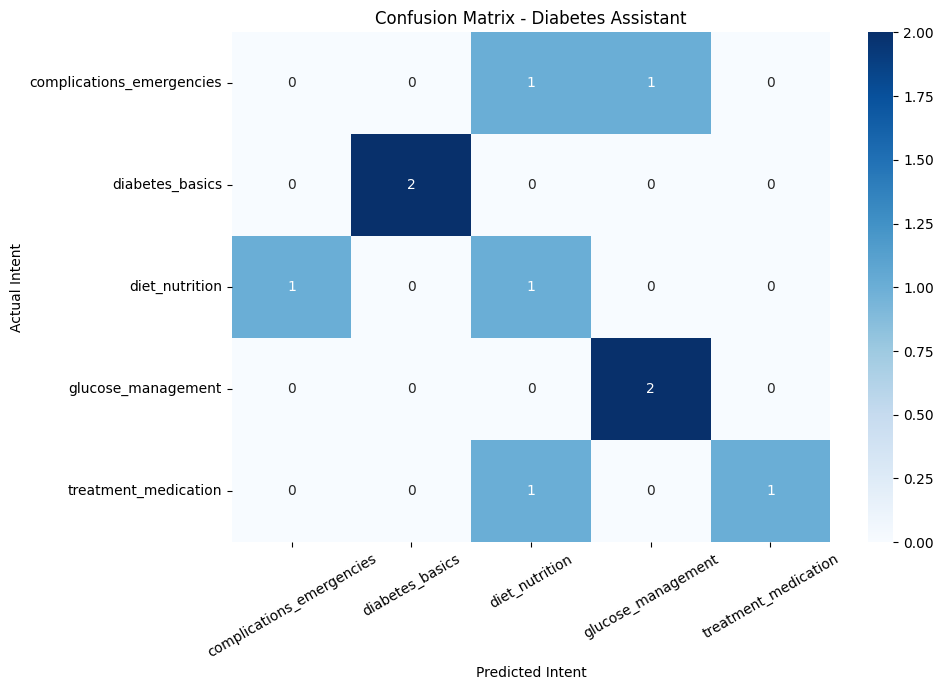

In [8]:
accuracy = accuracy_score(y_test, y_pred)

precision = precision_score(
    y_test,
    y_pred,
    average='weighted',
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    average='weighted',
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    average='weighted',
    zero_division=0
)


print("MODEL EVALUATION RESULTS")

print("--------------------------------")

print("Accuracy:", round(accuracy, 4))

print("Precision:", round(precision, 4))

print("Recall:", round(recall, 4))

print("F1 Score:", round(f1, 4))

print("\nClassification Report:\n")

print(
    classification_report(
        y_test,
        y_pred,
        zero_division=0
    )
)


# Confusion Matrix

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=model.classes_
)

plt.figure(figsize=(10, 7))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=model.classes_,
    yticklabels=model.classes_
)

plt.xlabel("Predicted Intent")

plt.ylabel("Actual Intent")

plt.title("Confusion Matrix - Diabetes Assistant")

plt.xticks(rotation=30)

plt.yticks(rotation=0)

plt.tight_layout()

plt.show()

In [9]:
knowledge_base = {

    "diabetes_basics": """

    DIABETES BASICS

    Diabetes is a chronic medical condition in which blood glucose
    levels become elevated because the body does not produce enough
    insulin or cannot use insulin effectively.

    Main types:

    1. Type 1 Diabetes:
       The immune system attacks insulin-producing cells.

    2. Type 2 Diabetes:
       The body becomes resistant to insulin or does not produce
       enough insulin.

    3. Gestational Diabetes:
       Diabetes that develops during pregnancy.

    Common symptoms include frequent urination, increased thirst,
    increased hunger, fatigue and blurred vision.

    Diabetes management requires medical monitoring and appropriate
    lifestyle changes.

    """,

    "glucose_management": """

    BLOOD GLUCOSE MANAGEMENT

    Blood glucose monitoring helps individuals understand their
    glucose levels.

    Common tests include:

    1. Fasting Blood Glucose.
    2. Post Meal Blood Glucose.
    3. HbA1c Test.
    4. Continuous Glucose Monitoring.

    For many non-pregnant adults with diabetes, common targets are:

    Before meals: 80-130 mg/dL.
    1-2 hours after beginning a meal: Below 180 mg/dL.

    HbA1c below 7% is a common target for many adults, but individual
    targets may differ.

    A glucose meter or continuous glucose monitor can help track
    glucose levels.

    Consult a healthcare professional for individual targets.

    """,

    "diet_nutrition": """

    DIET AND NUTRITION

    A balanced diet is important for diabetes management.

    Recommended food groups may include:

    1. Whole grains.
    2. Green vegetables.
    3. Legumes and pulses.
    4. Nuts and seeds.
    5. Fruits in appropriate portions.
    6. Lean protein sources.

    Foods that should generally be limited include sugary beverages,
    excessive sweets and highly processed foods.

    Eating fiber-rich foods can help support blood glucose control.

    Portion control and regular meal timing are also useful.

    Individual meal plans should consider medical needs and
    recommendations from a registered dietitian.

    """,

    "treatment_medication": """

    TREATMENT AND MEDICATION

    Diabetes treatment depends on the type of diabetes and
    individual medical conditions.

    Common approaches include:

    1. Insulin therapy.
    2. Oral medications such as metformin.
    3. Regular physical activity.
    4. Healthy eating habits.
    5. Blood glucose monitoring.

    Insulin helps glucose enter body cells.

    Metformin is commonly prescribed for type 2 diabetes.

    Regular exercise can improve insulin sensitivity.

    Never start, stop or change medication without consulting
    a qualified healthcare professional.

    """,

    "complications_emergencies": """

    COMPLICATIONS AND EMERGENCIES

    Diabetes may cause several long-term complications.

    Common complications include:

    1. Diabetic neuropathy - nerve damage.
    2. Diabetic retinopathy - damage to the retina.
    3. Diabetic nephropathy - kidney damage.
    4. Cardiovascular diseases.

    Hypoglycemia means blood glucose below 70 mg/dL.

    Symptoms can include sweating, shaking, hunger, dizziness
    and confusion.

    Hyperglycemia means elevated blood glucose.

    Symptoms may include increased thirst, frequent urination
    and fatigue.

    Severe symptoms require immediate medical attention.

    """

}

print("Knowledge Base Created Successfully!")

for intent, information in knowledge_base.items():

    print("\nIntent:", intent)

    print("Information length:", len(information), "characters")

Knowledge Base Created Successfully!

Intent: diabetes_basics
Information length: 710 characters

Intent: glucose_management
Information length: 669 characters

Intent: diet_nutrition
Information length: 656 characters

Intent: treatment_medication
Information length: 591 characters

Intent: complications_emergencies
Information length: 629 characters


In [10]:
# Rule 1: Emergency keywords

emergency_keywords = [

    "unconscious",
    "unresponsive",
    "cannot wake",
    "can't wake",
    "unable to wake",
    "seizure",
    "convulsion",
    "not breathing",
    "difficulty breathing",
    "trouble breathing",
    "chest pain",
    "severe confusion",
    "fainting",
    "passed out",
    "severe hypoglycemia",
    "diabetic ketoacidosis",
    "vomiting blood"

]


# Rule 2: Healthcare keywords outside diabetes domain

healthcare_keywords = [

    "ankle",
    "fracture",
    "broken bone",
    "cancer",
    "malaria",
    "dengue",
    "fever",
    "migraine",
    "asthma",
    "pregnancy",
    "pneumonia",
    "appendicitis",
    "arthritis",
    "skin infection"

]


diabetes_domain_keywords = [

    "diabetes",
    "diabetic",
    "glucose",
    "blood sugar",
    "insulin",
    "hba1c",
    "hypoglycemia",
    "hyperglycemia",
    "sugar level",
    "blood glucose",
    "metformin",
    "diabetic diet",
    "thirst",
    "thirsty",
    "urination",
    "urinate",
    "urinating",
    "pancreas",
    "neuropathy",
    "retinopathy"

]


CONFIDENCE_THRESHOLD = 0.30


def is_emergency(query):

    query = query.lower()

    for keyword in emergency_keywords:

        if keyword in query:
            return True

    return False


def is_unsupported_healthcare_query(query):

    query = query.lower()

    has_healthcare_term = any(
        keyword in query
        for keyword in healthcare_keywords
    )

    has_diabetes_term = any(
        keyword in query
        for keyword in diabetes_domain_keywords
    )

    return has_healthcare_term and not has_diabetes_term


def contains_diabetes_domain(query):

    query = query.lower()

    return any(
        keyword in query
        for keyword in diabetes_domain_keywords
    )


print("Rule-based reasoning system created!")
print("Emergency rules:", len(emergency_keywords))
print("Healthcare domain rules:", len(healthcare_keywords))
print("Confidence threshold:", CONFIDENCE_THRESHOLD)

Rule-based reasoning system created!
Emergency rules: 17
Healthcare domain rules: 14
Confidence threshold: 0.3


In [11]:
def healthcare_assistant(query):

    query = query.strip()

    if not query:

        return "Please enter a valid healthcare query."


    # RULE 1: EMERGENCY ESCALATION

    if is_emergency(query):

        return """

        🚨 EMERGENCY ALERT!

        This query contains symptoms that may indicate a
        medical emergency.

        Please seek immediate medical attention.

        Call 112 in India or your local emergency number.

        If the person is unconscious or having a seizure,
        do not give food, drinks or medicine by mouth.

        If a glucose emergency is suspected, follow the
        emergency plan provided by a healthcare professional.

        Do not wait for this chatbot to provide further advice.

        """


    # RULE 2: UNSUPPORTED HEALTHCARE QUERY

    if is_unsupported_healthcare_query(query):

        return """

        UNSUPPORTED HEALTHCARE QUERY

        I am a Diabetes Care Information Assistant.

        I can provide general information about:

        1. Diabetes basics.
        2. Blood glucose management.
        3. Diet and nutrition.
        4. Treatment and medication.
        5. Diabetes complications.

        Your question appears to concern a different
        healthcare topic.

        Please consult an appropriate healthcare professional.

        """


    # NLP PREPROCESSING

    processed_tokens = preprocess(query)

    processed_query = " ".join(processed_tokens)

    # TF-IDF TRANSFORMATION

    query_vector = tfidf.transform([query])

    # RULE 3: LOW CONFIDENCE HANDLING

    if query_vector.nnz == 0:

        return """

        LOW CONFIDENCE QUERY

        I could not understand your query.

        Please rephrase it using simple words related
        to diabetes care.

        """


    probabilities = model.predict_proba(query_vector)[0]

    max_confidence = np.max(probabilities)

    predicted_intent = model.classes_[np.argmax(probabilities)]


    if max_confidence < CONFIDENCE_THRESHOLD:

        return """

        LOW CONFIDENCE QUERY

        The system is not sufficiently confident about
        understanding your question.

        Please provide more details or rephrase your query.

        """


    # RULE 4: DOMAIN VALIDATION

    if not contains_diabetes_domain(query):

        return """

        UNSUPPORTED QUERY

        This assistant is designed specifically for
        diabetes-related healthcare information.

        Please ask a question related to diabetes care.

        """


    # RULE 5: KNOWLEDGE BASE RETRIEVAL

    response = knowledge_base.get(
        predicted_intent,
        "Relevant information is not available."
    )


    # RULE 6: MEDICAL SAFETY DISCLAIMER

    final_response = f"""

    ---------------------------------------
       DIABETES CARE INFORMATION ASSISTANT
    ---------------------------------------

    Query: {query}

    Predicted Intent: {predicted_intent}

    Model Confidence: {max_confidence:.2%}

    Processed Tokens: {processed_tokens}

    ---------------------------------------
       RETRIEVED HEALTHCARE INFORMATION
    ---------------------------------------

    {response}

    ---------------------------------------
       MEDICAL DISCLAIMER
    ---------------------------------------

    This assistant provides general educational
    information only.

    It does not replace professional medical advice,
    diagnosis or treatment.

    Always consult a qualified healthcare professional
    before making medical decisions.

    ---------------------------------------

    """

    return final_response


print("Healthcare Cognitive Assistant integrated successfully!")

Healthcare Cognitive Assistant integrated successfully!


In [12]:
test_queries = [

    # 1. One query from each intent category

    "Explain the different types of diabetes.",

    "How can I measure my blood glucose levels?",

    "Which vegetables are good for diabetic patients?",

    "How does insulin therapy help diabetic people?",

    "What are the long term complications of diabetes?",


    # 2. Differently worded query

    "I feel thirsty throughout the day and frequently visit the bathroom.",


    # 3. Unsupported healthcare query

    "What should I do if I have a broken ankle?",


    # 4. Low confidence query

    "Purple clouds dance with seven silent umbrellas.",


    # 5. Emergency-related query

    "My diabetic father is unconscious and cannot wake up."

]


for i, query in enumerate(test_queries, 1):

    print("\n\n==========================================")

    print("TEST CASE:", i)

    print("==========================================")

    print("USER QUERY:", query)

    print("\nASSISTANT RESPONSE:")

    print(healthcare_assistant(query))

    print("\n==========================================")



TEST CASE: 1
USER QUERY: Explain the different types of diabetes.

ASSISTANT RESPONSE:


    ---------------------------------------
       DIABETES CARE INFORMATION ASSISTANT
    ---------------------------------------

    Query: Explain the different types of diabetes.

    Predicted Intent: diabetes_basics

    Model Confidence: 43.17%

    Processed Tokens: ['explain', 'different', 'type', 'diabetes']

    ---------------------------------------
       RETRIEVED HEALTHCARE INFORMATION
    ---------------------------------------

    

    DIABETES BASICS

    Diabetes is a chronic medical condition in which blood glucose
    levels become elevated because the body does not produce enough
    insulin or cannot use insulin effectively.

    Main types:

    1. Type 1 Diabetes:
       The immune system attacks insulin-producing cells.

    2. Type 2 Diabetes:
       The body becomes resistant to insulin or does not produce
       enough insulin.

    3. Gestational Diabetes:
      

In [13]:
# Enable interactive widgets in Google Colab

try:

    from google.colab import output
    output.enable_custom_widget_manager()

except ImportError:

    pass


# Create input area

query_input = widgets.Textarea(

    value='',

    placeholder='Enter your diabetes-related query here...',

    description='Query:',

    layout=widgets.Layout(
        width='100%',
        height='100px'
    )

)


# Create button

submit_button = widgets.Button(

    description='Ask Assistant',

    button_style='success',

    icon='check',

    layout=widgets.Layout(
        width='200px'
    )

)


# Output area

output_area = widgets.Output()


# Button functionality

def on_submit(button):

    with output_area:

        clear_output()

        queries = query_input.value.strip().split('\n')

        for query in queries:

            if query.strip():

                print("\nUSER:", query)

                print("\nASSISTANT:")

                print(healthcare_assistant(query))

                print("\n" + "=" * 70)


submit_button.on_click(on_submit)


# Display chatbot

display(

    widgets.HTML(
        value="""
        <h2>🩺 Diabetes Care Information Assistant</h2>
        <p>Welcome! Ask questions about diabetes, glucose
        management, nutrition, treatment and complications.</p>
        """
    ),

    query_input,

    submit_button,

    output_area

)

HTML(value='\n        <h2>🩺 Diabetes Care Information Assistant</h2>\n        <p>Welcome! Ask questions about …

Textarea(value='', description='Query:', layout=Layout(height='100px', width='100%'), placeholder='Enter your …

Button(button_style='success', description='Ask Assistant', icon='check', layout=Layout(width='200px'), style=…

Output()